# Geographic hazard exposure of bank credit

The India EM-DAT damage model (`india_emdat_damage_model.ipynb`) gives a posterior over where hydrometeorological events start and what they cost. This notebook combines that posterior with the district map of bank credit from `experiments/banking_camels/00_banking_data_eda.ipynb`, toward a posterior distribution of the credit exposed to events in a year.

In [1]:
import os

# A JAX Metal plugin is installed, so JAX is pinned to the CPU before anything imports it.
os.environ["JAX_PLATFORMS"] = "cpu"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor.sparse as ps
import pytensor.tensor as pt
import xarray as xr

from scipy.sparse import csr_matrix
from scipy.spatial import cKDTree

import climate_risk.data

from climate_risk.data.cell_samples import load_cell_unit_overlaps
from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.ghsl import POPULATION_EPOCHS, population_on_cells
from climate_risk.data.rbi import load_rbi_district_bank_credit
from climate_risk.data.world_bank import load_wb_data
from climate_risk.geo.crs import PROJECTED_CRS
from climate_risk.geo.raster import build_cell_grid, dissolve_place_boundary
from climate_risk.plotting import configure_plot_style

configure_plot_style(add_grid=True)
cache_dir = Path.cwd().parents[1] / "data"
fit_path = Path("fits/16a_emdat_india_hydrometeorological_affected_share_bins_88_nuts.nc")

ISO = "IND"
RESOLUTION_KM = 25.0
PANEL_TITLE_SIZE = 12
FIGURE_TITLE_SIZE = 15
SEED = 20261120

## The fitted damage model

The posterior's rate of event centers per atom, its year effect, and the parameters that set each event's deaths, people affected and damage.

In [2]:
POSTERIOR_VARIABLES = ["log_rate",
                       "year_effect",
                       "indicator_intercept",
                       "loading",
                       "exposure_elasticity",
                       "income_coefficient",
                       "indicator_sd"]

with xr.open_datatree(fit_path) as fit:
    posterior = fit["posterior"].to_dataset()[POSTERIOR_VARIABLES].load()

posterior.sizes

Frozen({'chain': 8, 'draw': 250, 'atom': 5607, 'year': 34, 'indicator': 3, 'class': 1})

## Atoms

The damage model's atoms are the cells of a 25 km lattice over India's GADM boundary, including the territories GADM files under disputed-territory codes. The lattice is rebuilt the same way here, and its cells must line up with the posterior's atoms.

In [3]:
gadm_codes = (ISO, *administered_territories(iso=ISO, cache_dir=cache_dir))
gadm_states = pd.concat([load_units_in_country(iso=code, level=1, cache_dir=cache_dir) for code in gadm_codes], ignore_index=True)
gadm_districts = pd.concat([load_units_in_country(iso=code, level=2, cache_dir=cache_dir) for code in gadm_codes], ignore_index=True)
boundary = dissolve_place_boundary(gadm_states[["geometry"]], iso3=ISO)

grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
assert n_atoms == posterior.sizes["atom"], f"{n_atoms} atoms against {posterior.sizes['atom']} in the posterior"

## Where events start

The yearly rate of event centers at each atom, recorded or not, is $e^{\text{log rate}_a}$ times the year effect averaged over the record's years. Both are taken per posterior draw.

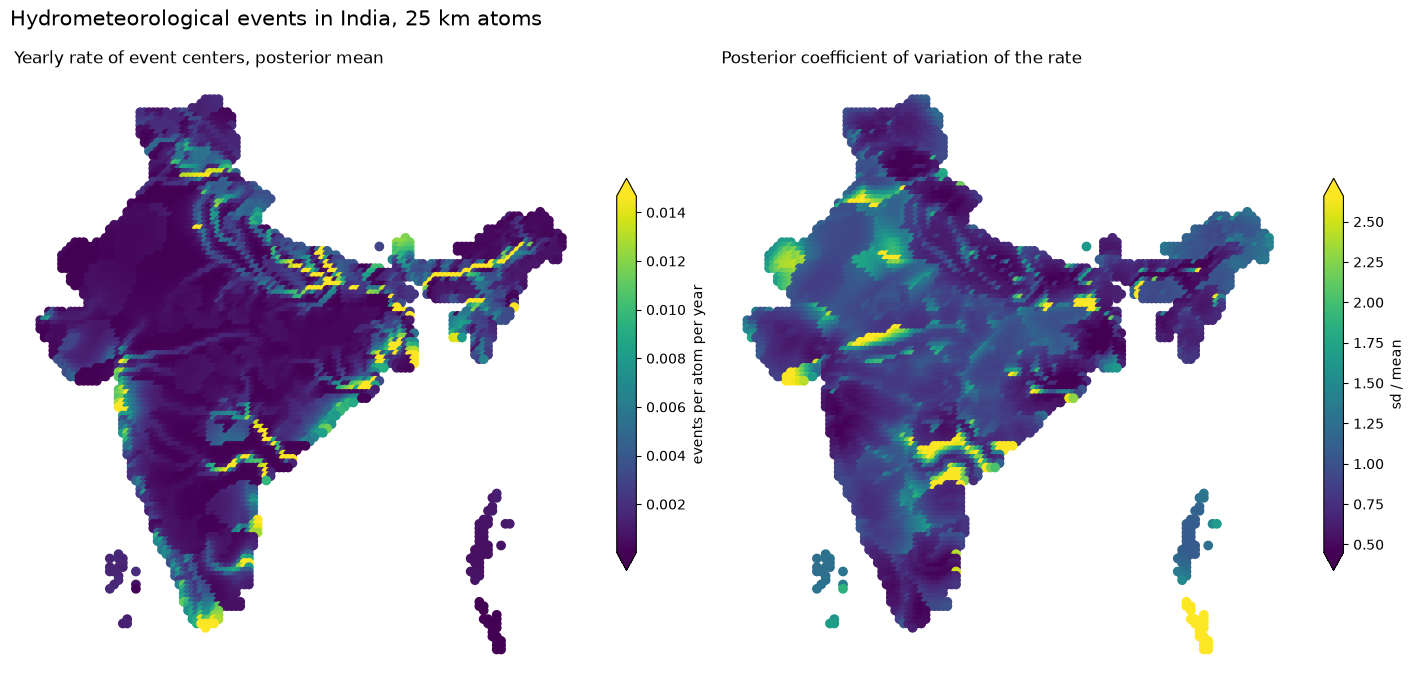

In [4]:
yearly_rate = np.exp(posterior["log_rate"]) * np.exp(posterior["year_effect"]).mean("year")
rate_summary = atoms.assign(mean_rate=yearly_rate.mean(("chain", "draw")).to_numpy(),
                            rate_spread=(yearly_rate.std(("chain", "draw")) / yearly_rate.mean(("chain", "draw"))).to_numpy())

fig, axes = plt.subplots(ncols=2,
                         figsize=(14, 7),
                         layout="constrained")
for ax, column, title, label in [(axes[0], "mean_rate", "Yearly rate of event centers, posterior mean", "events per atom per year"),
                                 (axes[1], "rate_spread", "Posterior coefficient of variation of the rate", "sd / mean")]:
    low, high = rate_summary[column].quantile([0.02, 0.98])
    rate_summary.plot(ax=ax,
                      column=column,
                      cmap="viridis",
                      vmin=low,
                      vmax=high,
                      legend=True,
                      legend_kwds={"label": label, "shrink": 0.6})
    ax.set_title(title, loc="left", fontsize=PANEL_TITLE_SIZE)
    ax.set_axis_off()
fig.suptitle("Hydrometeorological events in India, 25 km atoms", x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE);

## Credit on atoms

Bank credit outstanding in 2026 by district and bank group, from BSR-1, moved onto GADM districts with the crosswalk `rbi_district_gadm.csv` as in `experiments/banking_camels/00_banking_data_eda.ipynb`. Each GADM district's credit is then spread over the atoms it overlaps in proportion to their 2025 GHS-POP population inside the district, on the view that credit sits where people and firms are.

In [5]:
CREDIT_YEAR = 2026
POPULATION_EPOCH = 2025
LAKH_CRORE = 1e5

bank_credit = load_rbi_district_bank_credit(cache_dir)
district_credit = (bank_credit[bank_credit["year"] == CREDIT_YEAR]
                   .groupby(["state", "district", "bank_group"], observed=True)["amount_outstanding"].sum()
                   .unstack("bank_group", fill_value=0.0))
district_credit.columns = district_credit.columns.astype(str).str.capitalize()

crosswalk = pd.read_csv(Path(climate_risk.data.__file__).parent / "rbi_district_gadm.csv")
crosswalk["weight"] = 1 / crosswalk.groupby(["rbi_state", "rbi_district"])["gid"].transform("size")

linked = crosswalk.merge(district_credit.rename_axis(["rbi_state", "rbi_district"]).reset_index().astype({"rbi_state": str, "rbi_district": str}),
                         on=["rbi_state", "rbi_district"])
gadm_credit = linked[district_credit.columns].mul(linked["weight"], axis=0).groupby(linked["gid"]).sum()

In [6]:
people = population_on_cells(grid=grid, epoch=POPULATION_EPOCH, cache_dir=cache_dir)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

pairs = load_cell_unit_overlaps(grid=grid, units=gadm_districts, cache_dir=cache_dir)
pairs = pairs.assign(atom=column_of_cell.loc[pairs["cell_id"]].to_numpy())
# The people of an atom inside a district, taking people as spread evenly over the atom; a district with nobody in it falls back to area.
pairs["people_inside"] = people[pairs["atom"]] * pairs["coverage"]
district_people = pairs.groupby("gid")["people_inside"].transform("sum")
pairs["share"] = np.where(district_people > 0,
                          pairs["people_inside"] / district_people,
                          pairs["coverage"] / pairs.groupby("gid")["coverage"].transform("sum"))

allocated = pairs[["atom", "gid", "share"]].merge(gadm_credit, left_on="gid", right_index=True)
atom_credit = (allocated[district_credit.columns].mul(allocated["share"], axis=0)
               .groupby(allocated["atom"]).sum()
               .reindex(range(n_atoms), fill_value=0.0))

pd.DataFrame({"BSR-1, lakh crore": district_credit.sum() / LAKH_CRORE,
              "on atoms, lakh crore": atom_credit.sum() / LAKH_CRORE}).round(2)

,"BSR-1, lakh crore","on atoms, lakh crore"
Foreign banks,7.17,7.17
Private sector banks,84.45,84.45
Public sector banks,113.34,113.34
Regional rural banks,5.98,5.98
Small finance banks,3.40,3.40


## Footprints

An event exposes the credit in every atom whose center lies within 50 km of its own, the radius the damage model reads an event's exposed population over.

In [7]:
FOOTPRINT_KM = 50.0

projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
neighborhoods = cKDTree(atom_xy).query_ball_point(atom_xy, r=FOOTPRINT_KM * 1_000.0)
footprint = csr_matrix((np.ones(sum(len(found) for found in neighborhoods)),
                        (np.repeat(np.arange(n_atoms), [len(found) for found in neighborhoods]), np.concatenate(neighborhoods))),
                       shape=(n_atoms, n_atoms))

f"{np.median([len(found) for found in neighborhoods]):.0f} atoms in the median footprint"

'9 atoms in the median footprint'

## Simulated years

Each simulated year stands for 2026: the credit map is 2026's, and the hazard is that of the last ten record years, 2014 to 2023. The year effect rises over the record, from a posterior mean of 0.76 in the 1990s to 1.18 in the last decade, so drawing from the whole record would understate the present rate.

Each posterior draw simulates 2,000 years. A simulated year takes the year effect of one of the last ten record years at random, so the variation between years carries into the simulation, and its events start at each atom as a Poisson count with that draw's rate. The credit a year exposes is the credit inside the union of its events' footprints, so credit hit by two events in the same year counts once.

In [8]:
YEARS_PER_DRAW = 2_000
HAZARD_YEARS = np.arange(2014, 2024)

credit = atom_credit.to_numpy()
hazard_year_index = np.flatnonzero(np.isin(posterior["year"], HAZARD_YEARS))
coords = {"atom": posterior["atom"].to_numpy(),
          "year": posterior["year"].to_numpy(),
          "simulated_year": np.arange(YEARS_PER_DRAW),
          "bank_group": atom_credit.columns.to_numpy()}

with pm.Model(coords=coords) as exposure_model:
    log_rate = pm.Flat("log_rate", dims="atom")
    year_effect = pm.Flat("year_effect", dims="year")

    hazard_year = pm.Categorical("hazard_year", p=np.full(len(HAZARD_YEARS), 1 / len(HAZARD_YEARS)), dims="simulated_year")
    events = pm.Poisson("events",
                        mu=pt.exp(year_effect[hazard_year_index][hazard_year])[:, None] * pt.exp(log_rate)[None, :],
                        dims=("simulated_year", "atom"))

    hit = pt.gt(ps.structured_dot(ps.as_sparse_variable(footprint), events.T.astype("float64")), 0)
    pm.Deterministic("exposed_share",
                     pt.dot(hit.T.astype("float64"), credit) / credit.sum(axis=0),
                     dims=("simulated_year", "bank_group"))

exposed_share = (pm.sample_posterior_predictive(posterior[["log_rate", "year_effect"]],
                                                model=exposure_model,
                                                var_names=["exposed_share"],
                                                random_seed=SEED)
                 .posterior_predictive["exposed_share"]
                 .stack(sample=("chain", "draw")))

Sampling: [events, hazard_year]


Output()

## Value at risk

For each bank group, the share of its credit exposed in a year: the mean, the 95th and 99th percentiles, and the 99% expected shortfall, the mean over the worst 1% of years. Each statistic is computed over each posterior draw's simulated years, and the table gives its posterior median with a 90% interval across draws.

In [9]:
def expected_shortfall(shares, level):
    """The mean share over the simulated years at or above the ``level`` quantile, per draw and bank group."""
    threshold = shares.quantile(level, dim="simulated_year")
    return shares.where(shares >= threshold).mean("simulated_year").drop_vars("quantile")


risk_by_draw = xr.Dataset({"mean": exposed_share.mean("simulated_year"),
                           "95% VaR": exposed_share.quantile(0.95, dim="simulated_year").drop_vars("quantile"),
                           "99% VaR": exposed_share.quantile(0.99, dim="simulated_year").drop_vars("quantile"),
                           "99% expected shortfall": expected_shortfall(exposed_share, level=0.99)})
summary = risk_by_draw.quantile([0.05, 0.5, 0.95], dim="sample")


def with_interval(statistic):
    """Each bank group's posterior median of a statistic, in percent, with its 90% interval."""
    low, middle, high = (100 * summary[statistic].sel(quantile=level) for level in (0.05, 0.5, 0.95))
    return [f"{m:.1f}% ({lo:.1f} to {hi:.1f})" for lo, m, hi in zip(low.values, middle.values, high.values, strict=True)]


pd.DataFrame({statistic: with_interval(statistic) for statistic in risk_by_draw.data_vars},
             index=pd.Index(exposed_share["bank_group"].values, name="share of the group's credit exposed in a year"))

,mean,95% VaR,99% VaR,99% expected shortfall
share of the group's credit exposed in a year,,,,
Foreign banks,8.6% (4.3 to 15.2),36.6% (27.1 to 40.3),59.6% (38.0 to 63.0),62.0% (44.8 to 66.2)
Private sector banks,6.1% (3.8 to 9.5),18.9% (16.3 to 23.2),28.0% (20.9 to 33.2),31.9% (24.5 to 35.3)
Public sector banks,6.0% (3.8 to 9.1),19.7% (15.3 to 22.8),28.7% (21.3 to 33.0),31.9% (24.8 to 34.6)
Regional rural banks,2.8% (2.4 to 3.3),4.8% (4.2 to 5.6),5.8% (5.0 to 6.8),6.3% (5.5 to 7.4)
Small finance banks,4.2% (2.9 to 6.0),10.5% (8.1 to 13.4),14.0% (10.6 to 16.1),15.3% (12.3 to 17.5)


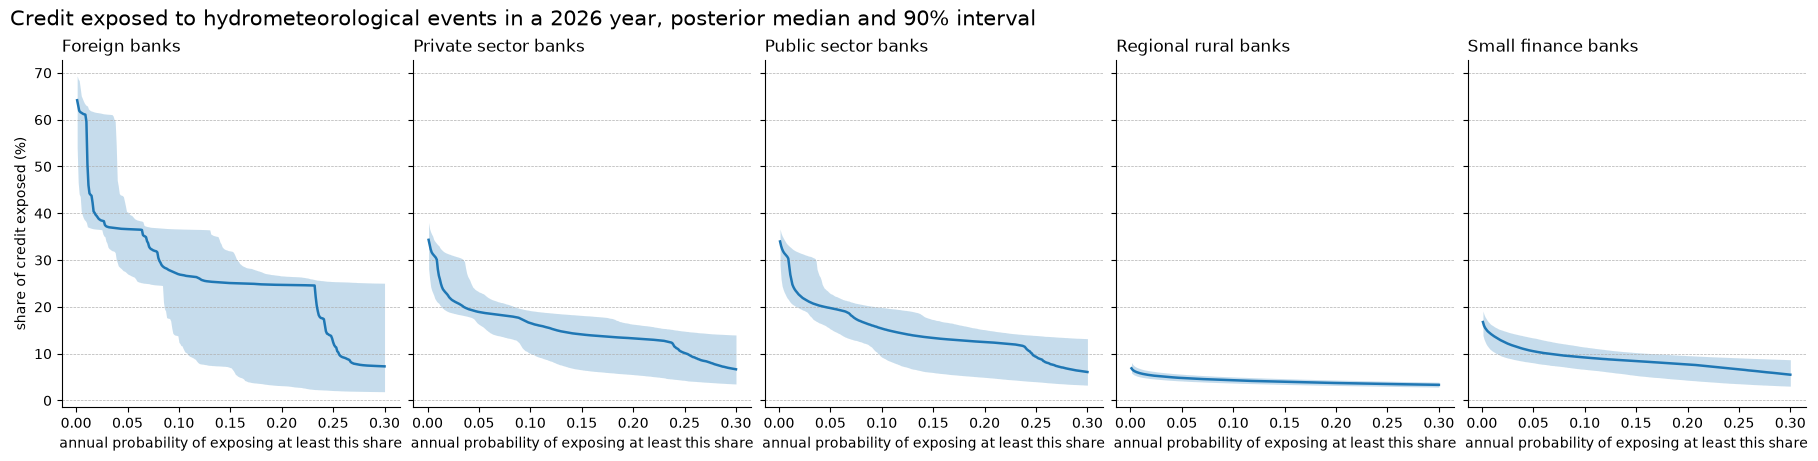

In [10]:
EXCEEDANCE_PROBABILITIES = np.linspace(0.001, 0.3, 300)

curves = (exposed_share.quantile(1 - EXCEEDANCE_PROBABILITIES, dim="simulated_year")
          .rename(quantile="exceedance")
          .assign_coords(exceedance=EXCEEDANCE_PROBABILITIES))
bands = curves.quantile([0.05, 0.5, 0.95], dim="sample")

fig, axes = plt.subplots(ncols=exposed_share.sizes["bank_group"],
                         figsize=(18, 4.5),
                         sharey=True,
                         layout="constrained")
for ax, bank_group in zip(axes, exposed_share["bank_group"].values, strict=True):
    band = 100 * bands.sel(bank_group=bank_group)
    ax.fill_between(EXCEEDANCE_PROBABILITIES,
                    band.sel(quantile=0.05),
                    band.sel(quantile=0.95),
                    color="C0",
                    alpha=0.25,
                    linewidth=0)
    ax.plot(EXCEEDANCE_PROBABILITIES, band.sel(quantile=0.5), color="C0", lw=1.8)
    ax.grid(visible=False, axis="x")
    ax.set(xlabel="annual probability of exposing at least this share")
    ax.set_title(bank_group, loc="left", fontsize=PANEL_TITLE_SIZE)
axes[0].set_ylabel("share of credit exposed (%)")
fig.suptitle("Credit exposed to hydrometeorological events in a 2026 year, posterior median and 90% interval",
             x=0.0,
             ha="left",
             fontsize=FIGURE_TITLE_SIZE);

The tails are set by two atoms. The 25 km atom on south Mumbai holds 35% of foreign banks' credit, 12% of private sector banks' and 14% of public sector banks', and an event's footprint reaches it in about 7% of years. The atom on central Delhi holds 11%, 6% and 6%, and is reached in about 22% of years, which places the step in each curve near 0.23. Foreign banks' credit is the most concentrated, so their 99% expected shortfall is 62% of their book against 32% for the private and public sector groups. Regional rural banks lend across many rural districts and have at most 6% of their credit exposed at the 99% level.

Two features of the inputs drive these numbers. BSR-1 places credit in the district of utilization, and large borrowers booked in Mumbai and Delhi may operate elsewhere. The model's rate near Delhi is its highest anywhere, and how much of it reflects where EM-DAT geocodes Delhi's events rather than where they start is not checked here.

## Expected exposure by district

A district's expected credit exposed in a year sums its credit over the atoms holding it, each weighted by the probability that an event's footprint reaches the atom in a 2026 year. Under a draw's rate, an atom is reached in a year with year effect $u_y$ with probability $1 - e^{-u_y \lambda_a}$, where $\lambda_a$ sums the rate over every atom within 50 km. That probability is averaged over the 2014 to 2023 year effects, as in the simulation.

In [11]:
district_atom_credit = (allocated.assign(amount=allocated[district_credit.columns].sum(axis=1) * allocated["share"])
                        .pivot_table(index="gid", columns="atom", values="amount", aggfunc="sum", fill_value=0.0)
                        .reindex(columns=range(n_atoms), fill_value=0.0))

with pm.Model(coords=coords | {"gid": district_atom_credit.index.to_numpy()}) as district_exposure_model:
    log_rate = pm.Flat("log_rate", dims="atom")
    year_effect = pm.Flat("year_effect", dims="year")

    footprint_rate = ps.structured_dot(ps.as_sparse_variable(footprint), pt.exp(log_rate)[:, None])[:, 0]
    reached = 1 - pt.exp(-pt.exp(year_effect[hazard_year_index])[:, None] * footprint_rate[None, :])
    hit_probability = pm.Deterministic("hit_probability", reached.mean(axis=0), dims="atom")
    pm.Deterministic("expected_exposed", pt.dot(district_atom_credit.to_numpy(), hit_probability), dims="gid")

expected_exposed = pm.compute_deterministics(posterior[["log_rate", "year_effect"]],
                                             model=district_exposure_model,
                                             var_names=["expected_exposed"])["expected_exposed"]

Output()

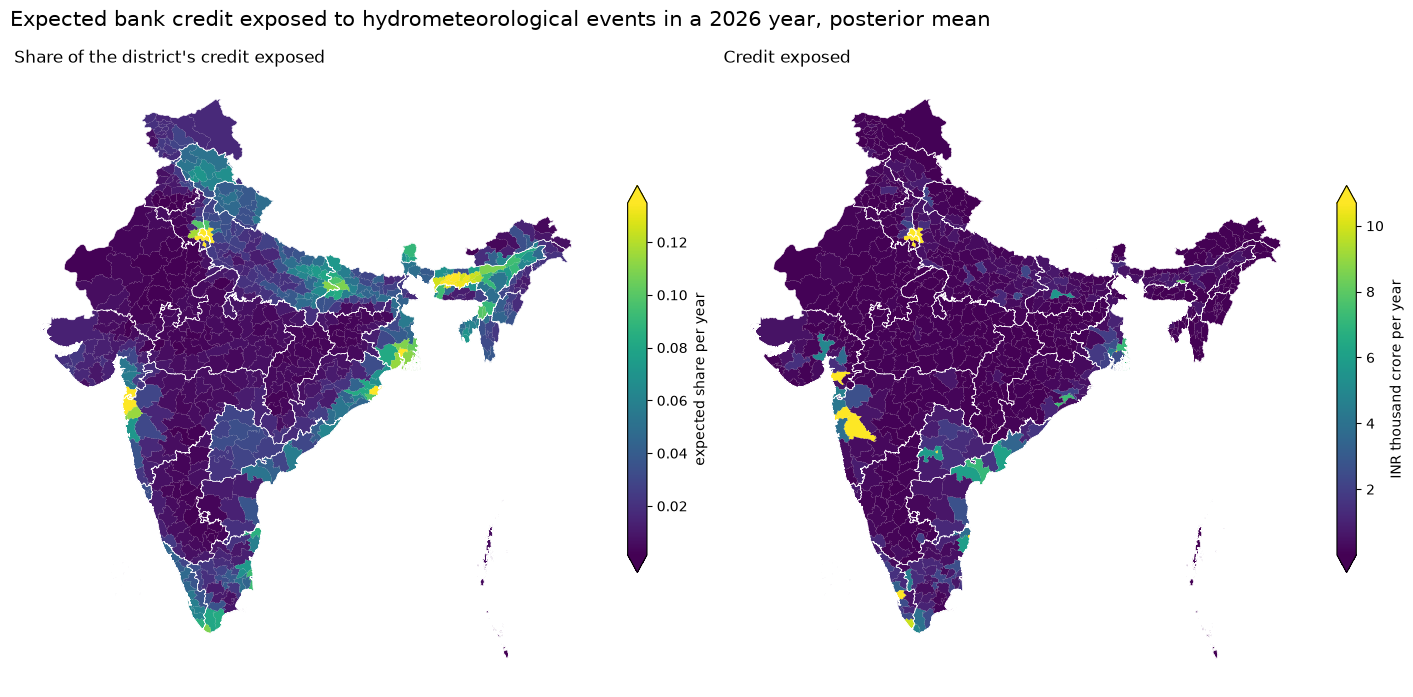

In [12]:
THOUSAND_CRORE = 1e3

district_exposure = gadm_districts.merge(pd.DataFrame({"expected_share": (expected_exposed.mean(("chain", "draw")) / district_atom_credit.sum(axis=1).to_numpy()).to_numpy(),
                                                       "expected_amount": expected_exposed.mean(("chain", "draw")).to_numpy() / THOUSAND_CRORE},
                                                      index=district_atom_credit.index),
                                         left_on="gid",
                                         right_index=True)

fig, axes = plt.subplots(ncols=2,
                         figsize=(14, 7),
                         layout="constrained")
for ax, column, title, label in [(axes[0], "expected_share", "Share of the district's credit exposed", "expected share per year"),
                                 (axes[1], "expected_amount", "Credit exposed", "INR thousand crore per year")]:
    low, high = district_exposure[column].quantile([0.02, 0.98])
    gadm_states.plot(ax=ax, color="0.9", edgecolor="white", linewidth=0.4)
    district_exposure.plot(ax=ax,
                           column=column,
                           cmap="viridis",
                           vmin=low,
                           vmax=high,
                           legend=True,
                           legend_kwds={"label": label, "shrink": 0.6})
    gadm_states.boundary.plot(ax=ax, color="white", linewidth=0.4)
    ax.set_title(title, loc="left", fontsize=PANEL_TITLE_SIZE)
    ax.set_axis_off()
fig.suptitle("Expected bank credit exposed to hydrometeorological events in a 2026 year, posterior mean",
             x=0.0,
             ha="left",
             fontsize=FIGURE_TITLE_SIZE);

Summed over districts, the expected credit exposed in a year is 1.33 lakh crore, 6.2% of all bank credit, the same share as the simulated years. Eight districts hold 70% of it. Delhi alone (GADM 4.1 holds the whole NCT as one district, named 'West') has 0.41 lakh crore, or 20% of its credit, exposed in an expected year. Mumbai City and Mumbai Suburban follow with 0.19 and 0.10 lakh crore, then Chennai, Gurgaon and Kolkata. The share map ranks districts differently. Districts with little credit along the Brahmaputra, the Ganges plain, the Odisha coast and the southern tip of Kerala and Tamil Nadu have 8 to 12% of their credit exposed in an expected year, but they contribute little to the national total.

## Return-period disasters

The damage notebook's return level for $T$ years is the damage a year's largest event exceeds with probability $1/T$. With $d$ a level of log damage, the yearly rate of events past it is

$$\Lambda(d) = \bar u \sum_a \lambda_a \left[1 - \Phi\left(\frac{d - \mu_a}{s}\right)\right], \qquad \mu_a = \alpha + \beta x_a + \gamma g, \qquad s = \sqrt{\ell^2 + \sigma^2},$$

where $\lambda_a$ is atom $a$'s rate, $\bar u$ the year effect averaged over 2014 to 2023, $x_a$ the centered log of the people within 50 km of the atom in 2025, binned as in the fit, and $g$ India's centered log GDP per head in 2025. The return level $d_T$ solves $\Lambda(d_T) = -\log(1 - 1/T)$.

Given an event past $d_T$, its center is at atom $a$ with probability proportional to $\lambda_a [1 - \Phi((d_T - \mu_a)/s)]$. Damage rises with the people near a center, so this weights populated atoms more than the rate alone. The credit a $T$-year disaster exposes is the credit within 50 km of its center, averaged over where it can happen.

In [13]:
EXPOSURE_EPOCHS = tuple(epoch for epoch in POPULATION_EPOCHS if 1990 <= epoch <= 2025)
REFERENCE_YEAR = 2005
EXPOSURE_BIN_WIDTH = 0.2
FIT_EXPOSURE_BINS = 88
INCOME_YEAR = 2025

neighbor_rows = np.repeat(np.arange(n_atoms), [len(found) for found in neighborhoods])
neighbor_columns = np.concatenate(neighborhoods)
log_exposure_by_epoch = np.stack([np.log1p(np.bincount(neighbor_rows,
                                                       weights=population_on_cells(grid=grid, epoch=epoch, cache_dir=cache_dir)[neighbor_columns],
                                                       minlength=n_atoms))
                                  for epoch in EXPOSURE_EPOCHS])
centered_exposure = log_exposure_by_epoch - np.median(log_exposure_by_epoch[EXPOSURE_EPOCHS.index(REFERENCE_YEAR)])

# The fit's bins span every epoch's exposure, and the fit reads each atom at its bin's center.
exposure_edges = np.arange(np.floor(centered_exposure.min() / EXPOSURE_BIN_WIDTH) * EXPOSURE_BIN_WIDTH,
                           centered_exposure.max() + EXPOSURE_BIN_WIDTH,
                           EXPOSURE_BIN_WIDTH)
exposure_bin_centers = (exposure_edges[:-1] + exposure_edges[1:]) / 2
assert len(exposure_bin_centers) == FIT_EXPOSURE_BINS, f"{len(exposure_bin_centers)} exposure bins against the fit's {FIT_EXPOSURE_BINS}"
atom_exposure = exposure_bin_centers[np.clip(np.digitize(centered_exposure[EXPOSURE_EPOCHS.index(2025)], exposure_edges) - 1,
                                             0,
                                             FIT_EXPOSURE_BINS - 1)]

world_bank = load_wb_data(cache_dir).filter(pl.col("country_code") == ISO).to_pandas().set_index("year")
log_income = np.log(world_bank["gdp_per_cap_usd"])
centered_income = log_income.loc[INCOME_YEAR] - log_income.loc[REFERENCE_YEAR]

In [14]:
RETURN_PERIODS = np.array([50, 100, 200])
# On log(1 + damage in thousands of US$), as in the damage notebook.
DAMAGE_LEVELS = np.linspace(6.0, 24.0, 361)
DAMAGE = list(posterior["indicator"].values).index("damage")

district_totals = district_atom_credit.sum(axis=1).to_numpy()
footprint_group_share = footprint @ credit / credit.sum(axis=0)
footprint_district_share = footprint @ district_atom_credit.to_numpy().T / district_totals


def normal_cdf(z):
    """The standard normal distribution function."""
    return 0.5 * pt.erfc(-z / np.sqrt(2.0))


with pm.Model(coords=coords | {"indicator": posterior["indicator"].to_numpy(),
                               "class": posterior["class"].to_numpy(),
                               "gid": district_atom_credit.index.to_numpy(),
                               "return_period": RETURN_PERIODS}) as return_period_model:
    log_rate = pm.Flat("log_rate", dims="atom")
    year_effect = pm.Flat("year_effect", dims="year")
    intercept = pm.Flat("indicator_intercept", dims=("indicator", "class"))
    loading = pm.Flat("loading", dims="indicator")
    elasticity = pm.Flat("exposure_elasticity", dims="indicator")
    income_coefficient = pm.Flat("income_coefficient", dims="indicator")
    noise_sd = pm.Flat("indicator_sd", dims="indicator")

    rate = pt.exp(log_rate) * pt.exp(year_effect[hazard_year_index]).mean()
    location = intercept[DAMAGE, 0] + elasticity[DAMAGE] * atom_exposure + income_coefficient[DAMAGE] * centered_income
    spread = pt.sqrt(loading[DAMAGE] ** 2 + noise_sd[DAMAGE] ** 2)

    exceedance = (rate[:, None] * normal_cdf((location[:, None] - DAMAGE_LEVELS) / spread)).sum(axis=0)
    return_level = pt.interp(-np.log1p(-1.0 / RETURN_PERIODS), exceedance[::-1], DAMAGE_LEVELS[::-1])
    pm.Deterministic("return_level", pt.expm1(return_level) / 1e6, dims="return_period")

    # Over (return period, atom): where an event past each return level is centered.
    center = rate[None, :] * normal_cdf((location[None, :] - return_level[:, None]) / spread)
    center = center / center.sum(axis=1, keepdims=True)
    pm.Deterministic("center_probability", center, dims=("return_period", "atom"))
    pm.Deterministic("group_exposed_share", pt.dot(center, footprint_group_share), dims=("return_period", "bank_group"))
    pm.Deterministic("district_exposed_share", pt.dot(center, footprint_district_share), dims=("return_period", "gid"))

return_period_exposure = pm.compute_deterministics(posterior[["log_rate", "year_effect", "indicator_intercept", "loading", "exposure_elasticity", "income_coefficient", "indicator_sd"]],
                                                   model=return_period_model,
                                                   var_names=["return_level", "center_probability", "group_exposed_share", "district_exposed_share"])

Output()

In [15]:
def plot_return_period_maps(district_shares, label, title):
    """One district map per return period of a percentage over (return_period, gid), on a shared color scale."""
    columns = (district_shares.to_pandas()
               .T
               .rename(columns=lambda period: f"{period}-year"))
    mapped = gadm_districts.merge(columns, left_on="gid", right_index=True)
    low, high = np.nanquantile(columns.to_numpy(), [0.02, 0.98])

    fig, axes = plt.subplots(ncols=len(RETURN_PERIODS),
                             figsize=(18, 7),
                             layout="constrained")
    for ax, column in zip(axes, columns.columns, strict=True):
        gadm_states.plot(ax=ax, color="0.9", edgecolor="white", linewidth=0.4)
        mapped.plot(ax=ax,
                    column=column,
                    cmap="viridis",
                    vmin=low,
                    vmax=high)
        gadm_states.boundary.plot(ax=ax, color="white", linewidth=0.4)
        ax.set_title(f"{column} damage event", loc="left", fontsize=PANEL_TITLE_SIZE)
        ax.set_axis_off()
    fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin=low, vmax=high), cmap="viridis"),
                 ax=axes,
                 shrink=0.6,
                 extend="both",
                 label=label)
    fig.suptitle(title, x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE)
    plt.show()


conditional_district_share = 100 * return_period_exposure["district_exposed_share"].mean(("chain", "draw"))

Events at least as large as the $T$-year return level occur at the yearly rate $-\log(1 - 1/T)$, about $1/T$. Scaling the exposure given the event by that rate gives each size class's expected share of credit exposed per year.

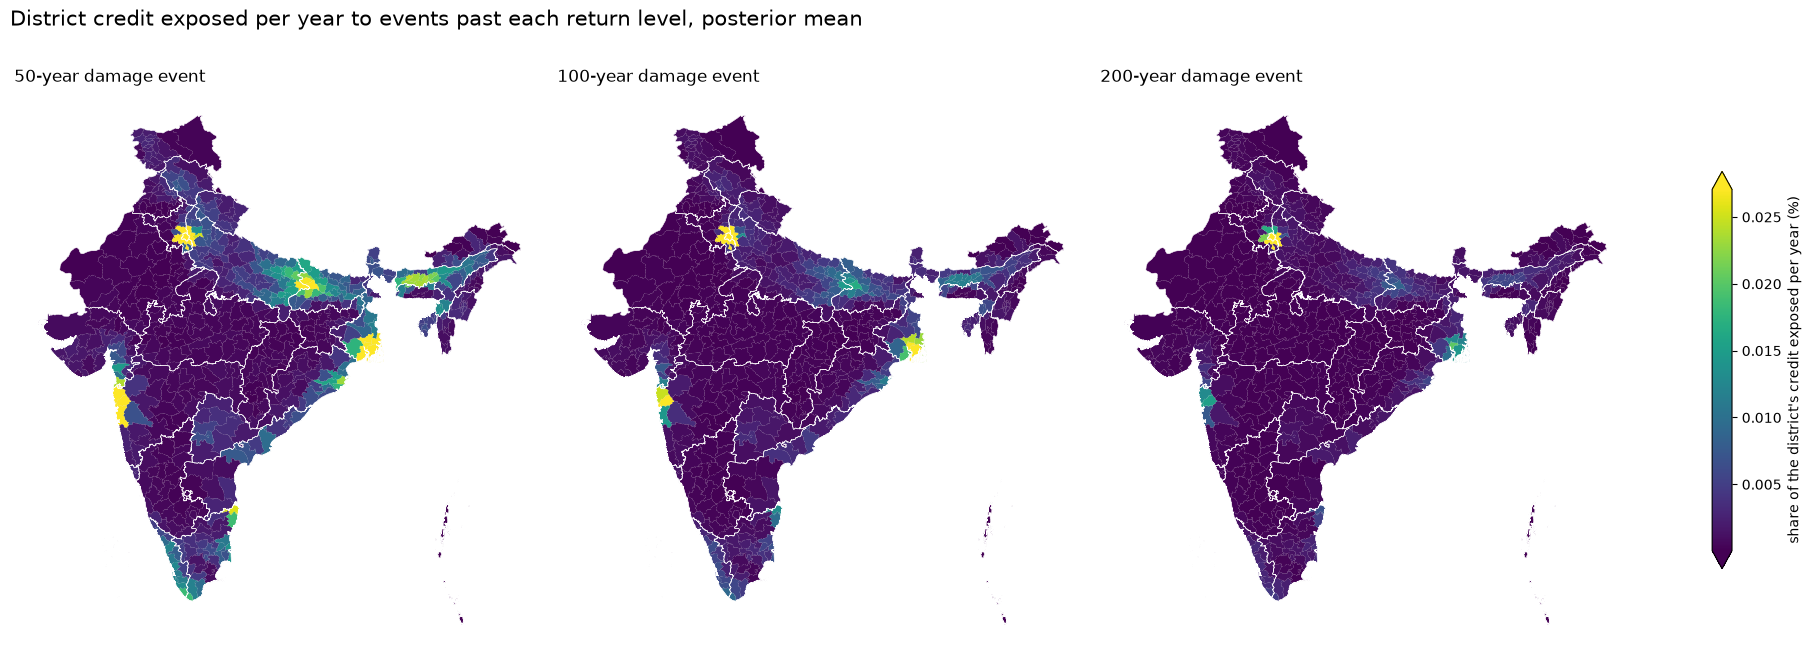

bank_group,Foreign banks,Private sector banks,Public sector banks,Regional rural banks,Small finance banks
return_period,,,,,
"50-year, basis points of credit per year",4.46,2.71,2.58,0.56,1.56
"100-year, basis points of credit per year",2.36,1.43,1.36,0.28,0.82
"200-year, basis points of credit per year",1.25,0.75,0.71,0.14,0.43


In [16]:
BASIS_POINTS = 1e4

yearly_event_rate = xr.DataArray(-np.log1p(-1.0 / RETURN_PERIODS), dims="return_period", coords={"return_period": RETURN_PERIODS})

plot_return_period_maps(conditional_district_share * yearly_event_rate,
                        label="share of the district's credit exposed per year (%)",
                        title="District credit exposed per year to events past each return level, posterior mean")

(BASIS_POINTS * return_period_exposure["group_exposed_share"] * yearly_event_rate).median(("chain", "draw")).to_pandas().rename(index=lambda period: f"{period}-year, basis points of credit per year").round(2)

The return levels are US$ 110, 182 and 294 billion for the 50, 100 and 200-year events, at posterior medians. Events past the 50-year level expose 4.5 basis points of foreign banks' credit per year, 2.7 of private sector banks' and 2.6 of public sector banks'. Each doubling of the return period roughly halves these figures, to 1.2, 0.8 and 0.7 basis points past the 200-year level. The halving is almost all frequency. An event's footprint is 50 km whatever its damage, so a larger event exposes no more ground, and its size shifts where it is likely to start only slightly, through the exposure elasticity.

These size classes are a small part of the yearly total. Public sector banks have about 600 basis points of credit exposed in an expected year, and events past the 50-year level contribute 2.6 of them. On the maps, Delhi, Mumbai and Kolkata carry the most exposure past the 50-year level, and past the 200-year level only Delhi stands out.